<a href="https://colab.research.google.com/github/adlinabil/231230025--Adli-Nabil-Mubarok--Machine-Learning/blob/main/praktikum_3_visualisasi_data_flights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kelompok: Flights Dataset - Visualisasi Data

**Modul:** Week-03 - Visualisasi Data  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Dataset:** `flights.csv` (jumlah penumpang pesawat per bulan, 1949-1960)

## Alur Notebook
1. Import library & load data
2. Eksplorasi data
3. Visualisasi 1 - Tren jangka panjang (line plot + rolling mean)
4. Visualisasi 2 - Pola musiman (heatmap + line plot per tahun)
5. Visualisasi 3 - Distribusi per bulan & pertumbuhan tahunan (box plot + bar plot)
6. Kesimpulan

---

## Kelompok E: Flights Dataset

### 🔗 Referensi Dataset
- **Sumber Data:** [Seaborn Flights Dataset](https://github.com/mwaskom/seaborn-data/blob/master/flights.csv)
- **Load Data:** `sns.load_dataset('flights')` atau `pd.read_csv('flights.csv', sep=';')`
- **Jenis:** Time Series / Regression (forecasting)
- **Samples:** 144 (data bulanan selama 12 tahun, 12 bulan x 12 tahun)
- **Features:** 3 (`year`, `month`, `passengers`)
- **Target:** `passengers` (jumlah penumpang pesawat per bulan)

### 📈 Karakteristik Data
- **Tipe Data Campuran:** Numerik diskret (`year`, `passengers`) dan kategorikal ordinal (`month`)
- **Fitur Waktu:** `year` (1949-1960) dan `month` (Januari-Desember)
- **Target:** Jumlah penumpang maskapai internasional per bulan (dalam ribuan)
- **Struktur:** Data deret waktu dengan frekuensi bulanan, tanpa missing value, dan tiap kombinasi tahun-bulan muncul tepat satu kali
- **Pola Umum:** Terdapat tren naik jangka panjang dan pola musiman yang berulang setiap tahun
- **Catatan Teknis:** File CSV yang kita pakai menggunakan pemisah titik koma (`;`), sehingga harus dibaca dengan `sep=';'`. Selain itu, `month` perlu diurutkan secara kronologis (bukan alfabetis) saat divisualisasikan
- **Domain:** Transportasi udara, yaitu analisis tren dan musiman permintaan penumpang

### Pertanyaan Diskusi
1. Bagaimana tren jumlah penumpang dari tahun ke tahun? Apakah pertumbuhannya lebih mendekati pola linear atau eksponensial?
2. Bulan apa saja yang menjadi puncak dan lembah jumlah penumpang? Apakah pola tersebut konsisten setiap tahun?
3. Apakah pola musiman berubah seiring waktu, misalnya selisih antara bulan tertinggi dan terendah semakin besar atau tetap?
4. Bagaimana distribusi jumlah penumpang di setiap bulan, dan bulan apa yang memiliki nilai tengah (median) tertinggi? Apa yang menyebabkan rentang data pada tiap bulan terlihat lebar?
5. Bagaimana laju pertumbuhan tahunan (year-over-year) jumlah penumpang? Tahun mana yang tumbuh paling cepat dan paling lambat dibanding rata-ratanya?

### Bahan Diskusi Visualisasi
- **Pertimbangkan:** line plot (+ rolling mean), line plot per tahun, heatmap (pivot bulan x tahun), box plot per bulan, bar plot pertumbuhan tahunan
- **Analisis:** tren jangka panjang, pola musiman, perubahan variasi dari waktu ke waktu, perbandingan antar bulan dan antar tahun
- **Fokus:** time series visualization, seasonal pattern, trend analysis, penyajian data pivot (heatmap)

## 1. Import Library & Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style seaborn (sama seperti praktikum)
sns.set_style("whitegrid")

**Catatan:** file `flights.csv` memakai pemisah **titik koma (`;`)**, jadi harus dibaca dengan `sep=';'`.  
Jika memakai Google Colab, upload dulu `flights.csv` ke folder Files (ikon folder di kiri).

In [ ]:
# Load data
df = pd.read_csv('flights.csv', sep=';')

# Urutan bulan yang benar (supaya tidak terurut A-Z)
urutan_bulan = ['January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December']
df['month'] = pd.Categorical(df['month'], categories=urutan_bulan, ordered=True)

# Kolom tanggal (berguna untuk sumbu x pada line plot)
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].cat.codes.add(1).astype(str) + '-01')

df.head()

,year,month,passengers,date
0,1949,January,112,1949-01-01
1,1949,February,118,1949-02-01
2,1949,March,132,1949-03-01
3,1949,April,129,1949-04-01
4,1949,May,121,1949-05-01


## 2. Eksplorasi Data

In [ ]:
print("=== EKSPLORASI DATA FLIGHTS ===")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")
print(f"\nStatistik Deskriptif (passengers):")
print(df['passengers'].describe())

=== EKSPLORASI DATA FLIGHTS ===
Shape: (144, 4)
Columns: ['year', 'month', 'passengers', 'date']

Data Types:
year                   int64
month               category
passengers             int64
date          datetime64[us]
dtype: object

Missing Values:
year          0
month         0
passengers    0
date          0
dtype: int64

Statistik Deskriptif (passengers):
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: passengers, dtype: float64


In [ ]:
# Jumlah penumpang per tahun dan rata-rata per bulan
print("=== TOTAL PENUMPANG PER TAHUN ===")
print(df.groupby('year')['passengers'].sum())

print("\n=== RATA-RATA PENUMPANG PER BULAN ===")
print(df.groupby('month', observed=True)['passengers'].mean().round(1))

=== TOTAL PENUMPANG PER TAHUN ===
year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
Name: passengers, dtype: int64

=== RATA-RATA PENUMPANG PER BULAN ===
month
January      241.8
February     235.0
March        270.2
April        267.1
May          271.8
June         311.7
July         351.3
August       351.1
September    302.4
October      266.6
November     232.8
December     261.8
Name: passengers, dtype: float64


**Temuan awal:**
- Data lengkap: 144 baris (12 tahun x 12 bulan) dan tidak ada missing value.
- Jumlah penumpang berkisar dari 104 sampai 622 (ribu penumpang), rata-rata sekitar 280.

## 3. Visualisasi 1: Tren Jangka Panjang

**Pertanyaan:** Bagaimana tren jumlah penumpang dari tahun ke tahun?  
**Plot:** Line plot deret waktu + rolling mean 12 bulan (rata-rata bergerak menghaluskan efek musiman sehingga tren terlihat jelas).

=== VISUALISASI 1: TREN JANGKA PANJANG ===


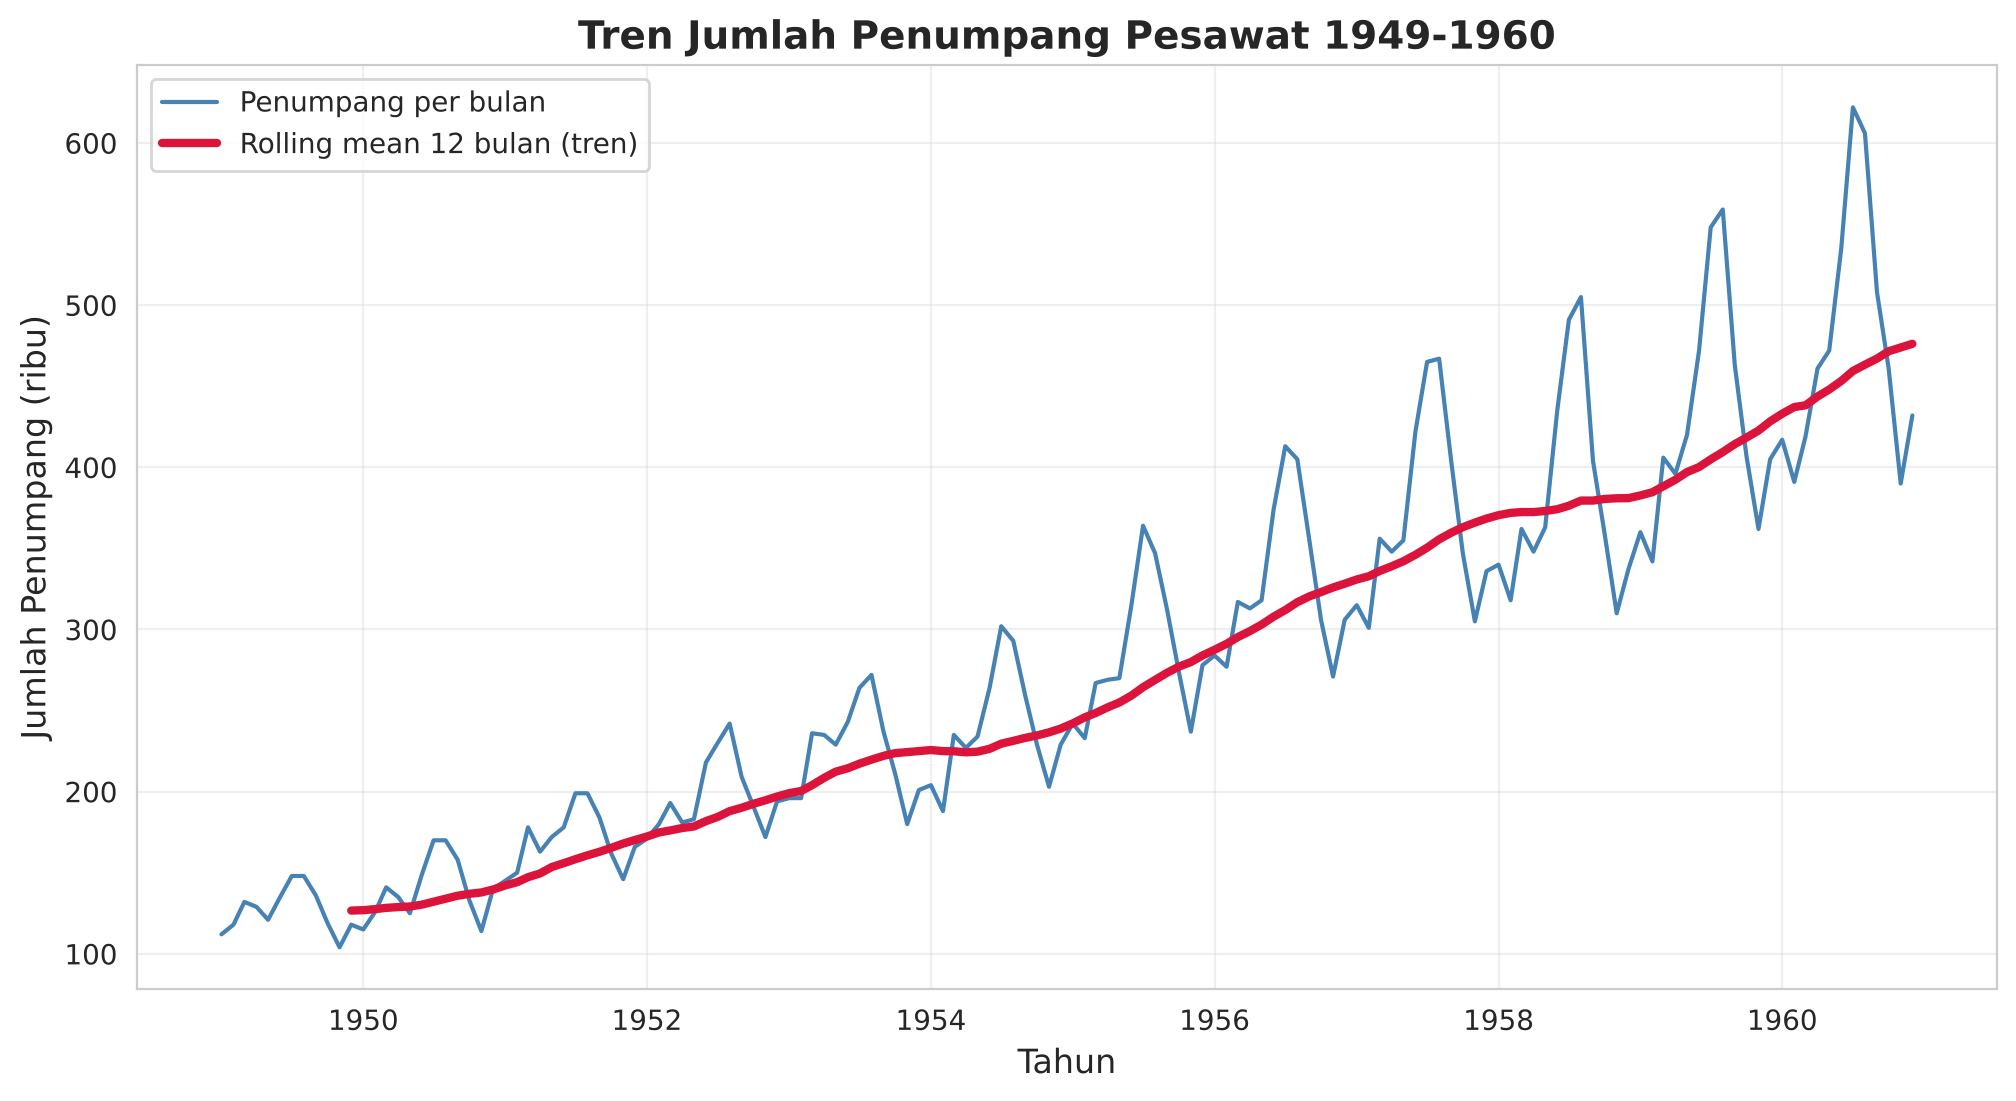

In [ ]:
print("=== VISUALISASI 1: TREN JANGKA PANJANG ===")

# Rolling mean 12 bulan = rata-rata 1 tahun penuh
df['rolling_12'] = df['passengers'].rolling(window=12).mean()

plt.figure(figsize=(12, 6))
plt.plot(df['date'], df['passengers'], label='Penumpang per bulan', color='steelblue', linewidth=1.5)
plt.plot(df['date'], df['rolling_12'], label='Rolling mean 12 bulan (tren)', color='crimson', linewidth=3)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Jumlah Penumpang (ribu)', fontsize=12)
plt.title('Tren Jumlah Penumpang Pesawat 1949-1960', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Insight Visualisasi 1:**
- Tren **naik konsisten** sepanjang 12 tahun: total penumpang per tahun naik dari 1.520 (1949) menjadi 5.714 (1960), atau sekitar **3,8 kali lipat**.
- Garis tren (merah) agak melengkung ke atas, jadi pertumbuhannya lebih mirip **eksponensial** daripada linear (perlu dicek lebih lanjut dengan model atau skala log).
- Garis biru bergelombang naik-turun secara teratur, ini tanda adanya **pola musiman** (dibahas di Visualisasi 2).

## 4. Visualisasi 2: Pola Musiman

**Pertanyaan:** Bulan apa yang menjadi puncak dan lembah? Apakah polanya berubah seiring waktu?  
**Plot:** Heatmap (pivot bulan x tahun) dan line plot per tahun.

=== VISUALISASI 2: POLA MUSIMAN ===


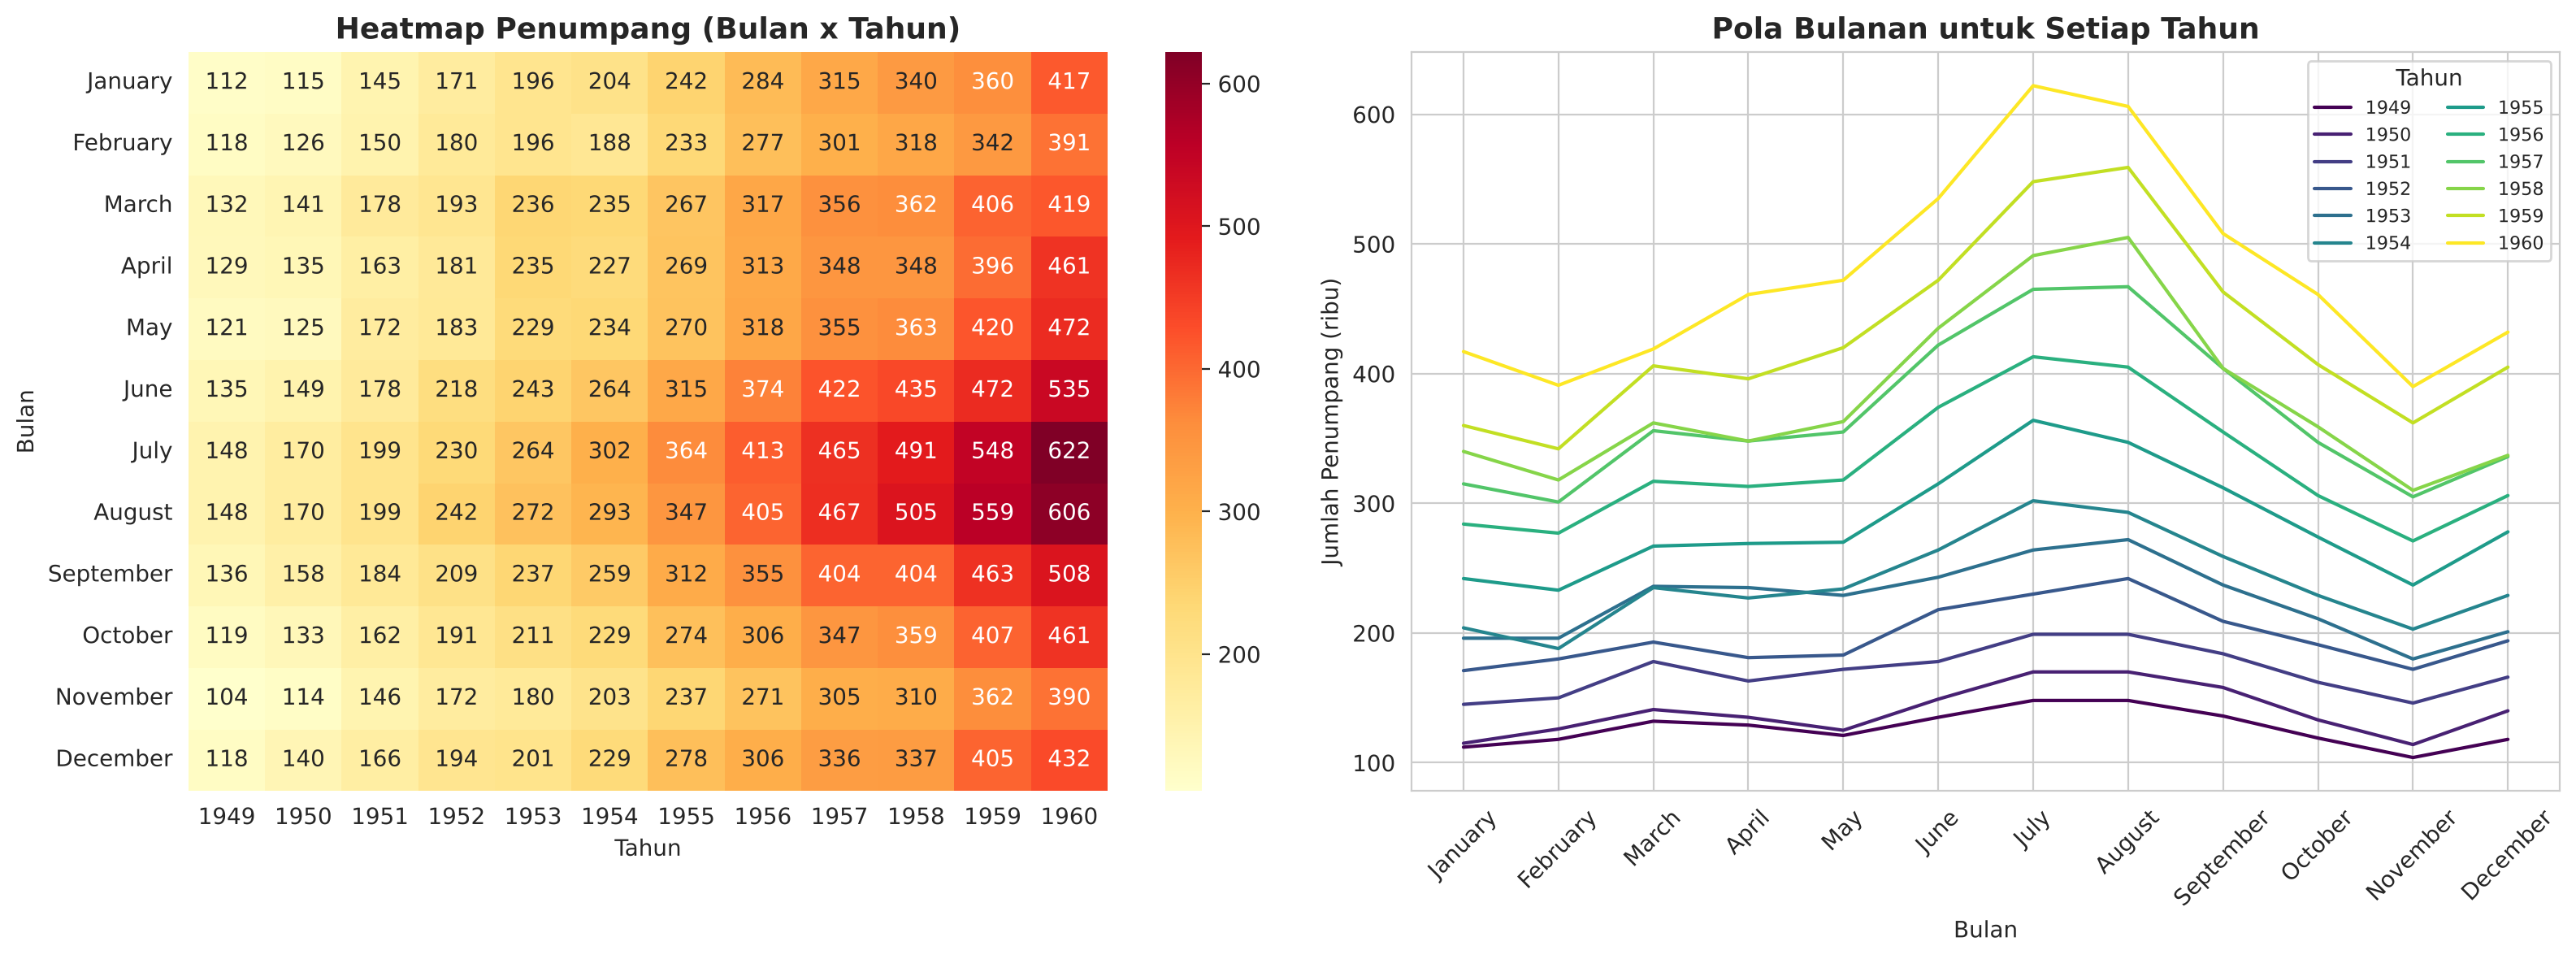


=== SELISIH BULAN TERTINGGI - TERENDAH PER TAHUN ===
year
1949     44
1950     56
1951     54
1952     71
1953     92
1954    114
1955    131
1956    142
1957    166
1958    195
1959    217
1960    232
Name: passengers, dtype: int64


In [ ]:
print("=== VISUALISASI 2: POLA MUSIMAN ===")

# Ubah data menjadi tabel: baris = bulan, kolom = tahun
pivot = df.pivot_table(index='month', columns='year', values='passengers', observed=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[0])
axes[0].set_title('Heatmap Penumpang (Bulan x Tahun)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('Bulan')

# Line plot per tahun (setiap garis = 1 tahun)
sns.lineplot(data=df, x='month', y='passengers', hue='year', palette='viridis', legend='full', ax=axes[1])
axes[1].set_title('Pola Bulanan untuk Setiap Tahun', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Bulan')
axes[1].set_ylabel('Jumlah Penumpang (ribu)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Tahun', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

# Selisih bulan tertinggi dan terendah dalam tiap tahun
print("\n=== SELISIH BULAN TERTINGGI - TERENDAH PER TAHUN ===")
print(df.groupby('year')['passengers'].agg(lambda s: s.max() - s.min()))

**Insight Visualisasi 2:**
- **Puncak** selalu di **Juli-Agustus** (musim liburan), **lembah** di **November** dan **Februari**.
- Bentuk pola bulanan **sama setiap tahun** (garis-garis sejajar), tetapi makin tinggi ke tahun-tahun akhir.
- Selisih antara bulan tertinggi dan terendah membesar dari **44** (1949) menjadi **232** (1960). Artinya ayunan musiman ikut membesar mengikuti tren naik.

## 5. Visualisasi 3: Distribusi per Bulan & Pertumbuhan Tahunan

**Pertanyaan:** Bagaimana distribusi tiap bulan, dan tahun mana yang pertumbuhannya tidak biasa?  
**Plot:** Box plot per bulan dan bar plot pertumbuhan year-over-year (YoY).

=== VISUALISASI 3: DISTRIBUSI & PERTUMBUHAN ===


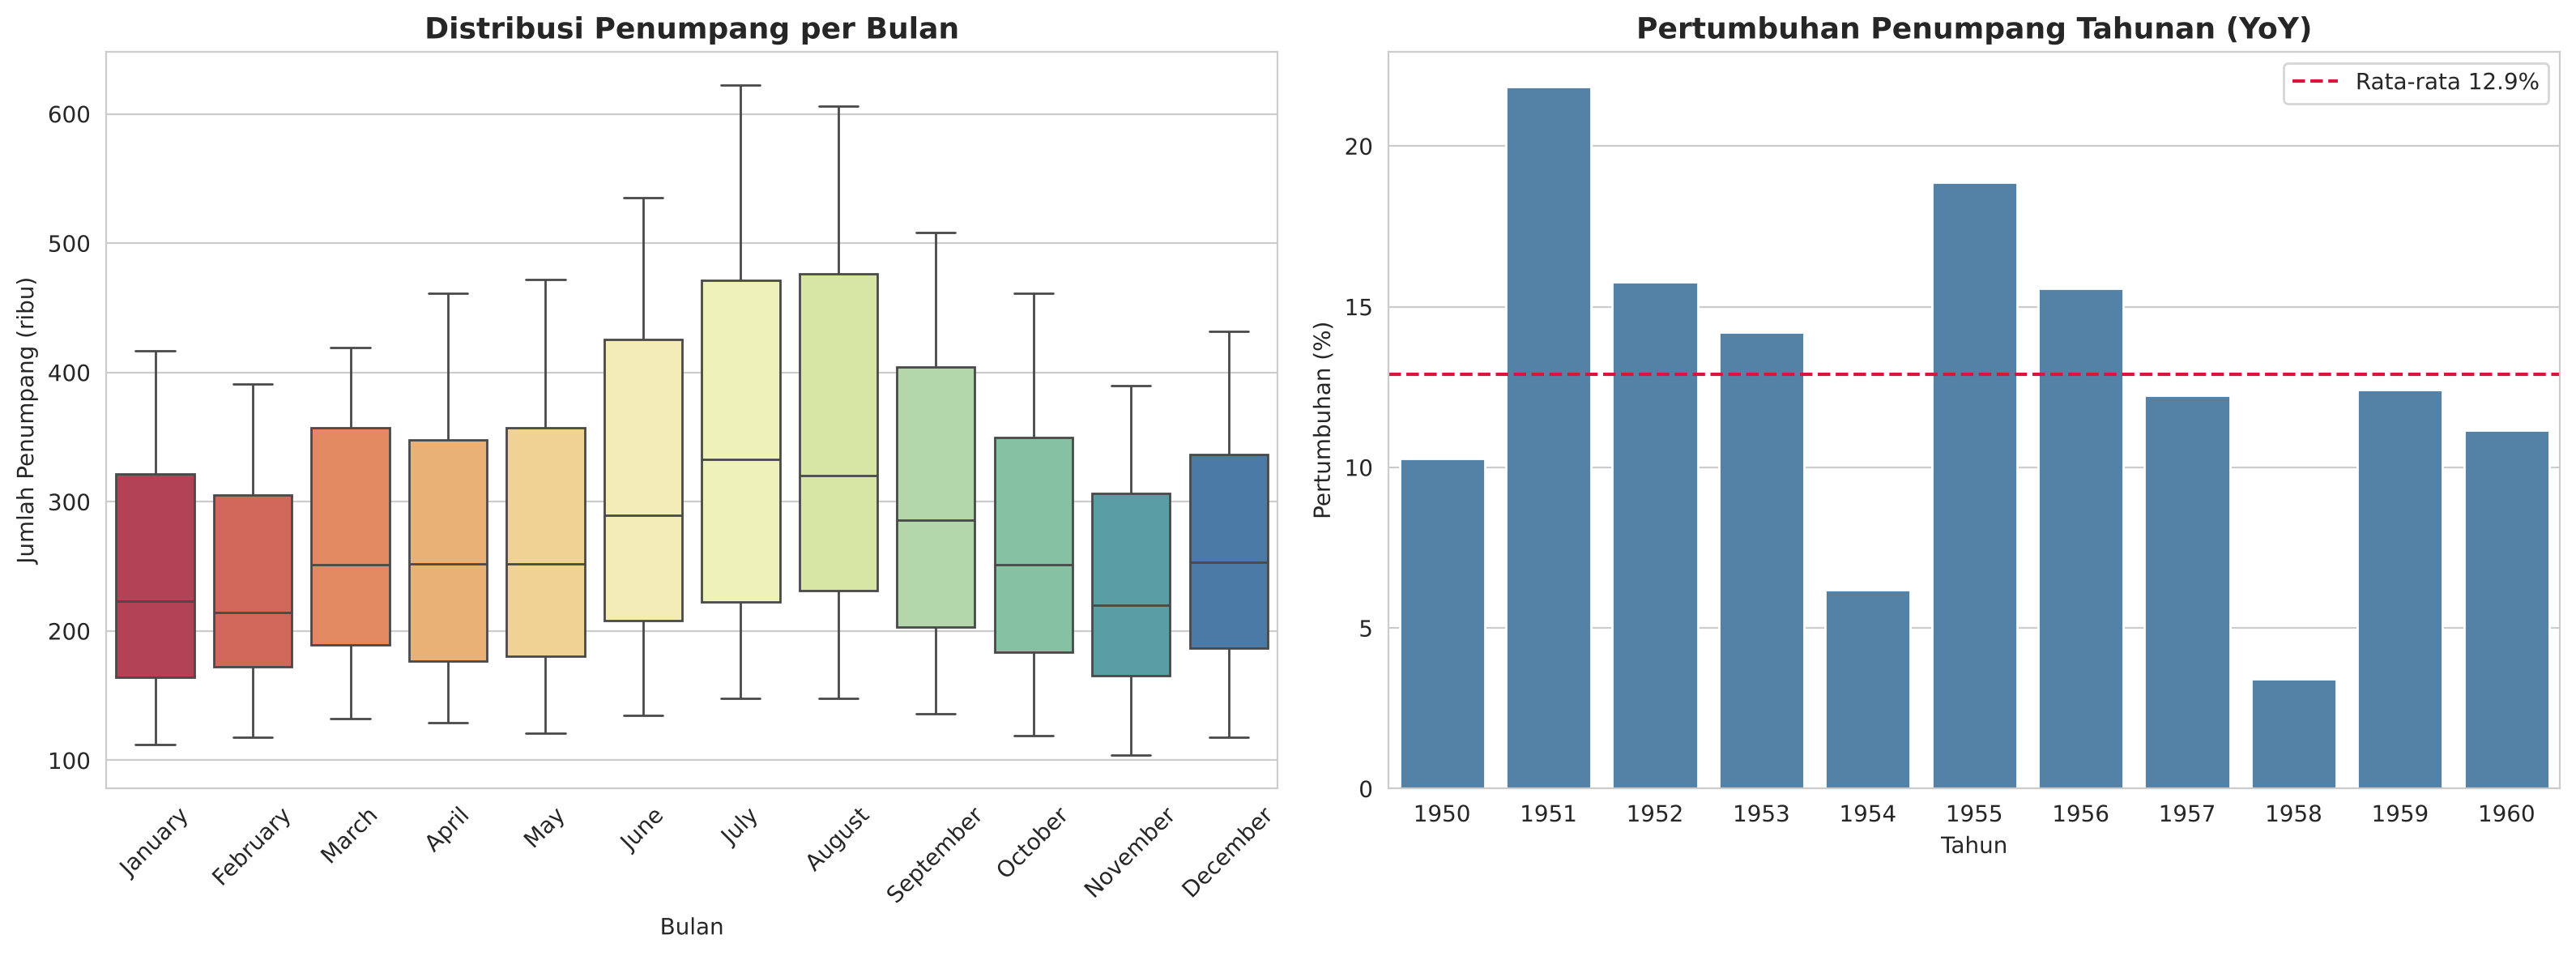

year
1950    10.3
1951    21.8
1952    15.8
1953    14.2
1954     6.2
1955    18.9
1956    15.6
1957    12.2
1958     3.4
1959    12.4
1960    11.2
Name: passengers, dtype: float64


In [ ]:
print("=== VISUALISASI 3: DISTRIBUSI & PERTUMBUHAN ===")

# Hitung pertumbuhan tahunan (%)
total_tahun = df.groupby('year')['passengers'].sum()
yoy = total_tahun.pct_change() * 100
yoy = yoy.dropna()   # tahun 1949 tidak punya pembanding

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box plot per bulan
sns.boxplot(data=df, x='month', y='passengers', hue='month', palette='Spectral', dodge=False, legend=False, ax=axes[0])
axes[0].set_title('Distribusi Penumpang per Bulan', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Bulan')
axes[0].set_ylabel('Jumlah Penumpang (ribu)')
axes[0].tick_params(axis='x', rotation=45)

# Bar plot pertumbuhan YoY
sns.barplot(x=yoy.index, y=yoy.values, color='steelblue', ax=axes[1])
axes[1].axhline(yoy.mean(), color='crimson', linestyle='--', label=f'Rata-rata {yoy.mean():.1f}%')
axes[1].set_title('Pertumbuhan Penumpang Tahunan (YoY)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Pertumbuhan (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(yoy.round(1))

**Insight Visualisasi 3:**
- Box plot memperlihatkan bulan **Juli dan Agustus** punya median tertinggi dan rentang (kotak) lebar. Rentang lebar ini terutama disebabkan **tren naik antar tahun**, bukan data yang berantakan, jadi box plot per bulan harus dibaca hati-hati.
- Pertumbuhan tahunan rata-rata sekitar **13%** (12,9%). Tahun **1951 (+21,8%)** dan **1955 (+18,9%)** tumbuh sangat cepat, sedangkan **1958 (+3,4%)** dan **1954 (+6,2%)** melambat.

## 6. Kesimpulan

### Jawaban Pertanyaan Diskusi

**1. Bagaimana tren jumlah penumpang dari tahun ke tahun? Apakah pertumbuhannya lebih mendekati linear atau eksponensial?**

Dari line plot dan rolling mean 12 bulan, jumlah penumpang naik terus dari 1949 sampai 1960. Total penumpang per tahun naik dari 1.520 menjadi 5.714, atau sekitar 3,8 kali lipat. Garis rolling mean-nya agak melengkung ke atas, jadi pertumbuhannya lebih mirip eksponensial daripada linear.

**2. Bulan apa saja yang menjadi puncak dan lembah? Apakah pola tersebut konsisten setiap tahun?**

Puncaknya ada di bulan Juli dan Agustus (rata-rata sekitar 351 ribu penumpang), kemungkinan karena musim liburan. Lembahnya di bulan November dan Februari (rata-rata sekitar 233 dan 235 ribu). Polanya konsisten setiap tahun, terlihat dari garis-garis di line plot per tahun yang bentuknya mirip dan sejajar, serta dari warna heatmap yang paling gelap selalu di Juli-Agustus.

**3. Apakah pola musiman berubah seiring waktu?**

Bentuk polanya sama, tapi ayunannya makin besar. Selisih antara bulan tertinggi dan terendah dalam satu tahun naik dari 44 di tahun 1949 menjadi 232 di tahun 1960. Artinya makin tinggi tren penumpang, makin besar juga naik-turun musimannya. Jadi pengaruh musim bukan angka tetap, tapi ikut membesar mengikuti tren.

**4. Bagaimana distribusi penumpang di tiap bulan? Bulan apa yang mediannya tertinggi, dan kenapa rentang datanya lebar?**

Dari box plot, bulan Juli dan Agustus punya median paling tinggi dibanding bulan lain. Kotak di tiap bulan terlihat lebar, tapi bukan karena datanya berantakan. Penyebabnya adalah tren naik antar tahun, karena satu bulan yang sama berisi data dari tahun 1949 yang masih kecil sampai 1960 yang sudah besar. Contohnya Juli 1949 hanya 148, sedangkan Juli 1960 sudah 622. Jadi box plot per bulan harus dibaca dengan hati-hati dan tidak bisa langsung dianggap sebagai variasi musiman saja.

**5. Bagaimana laju pertumbuhan tahunan (YoY)? Tahun mana yang tumbuh paling cepat dan paling lambat?**

Rata-rata pertumbuhan penumpang sekitar 12,9% per tahun. Pertumbuhan tidak sama rata setiap tahun. Yang paling cepat adalah tahun 1951 (+21,8%), disusul 1955 (+18,9%). Yang paling lambat adalah tahun 1958 (+3,4%), disusul 1954 (+6,2%). Jadi walaupun arah besarnya selalu naik, kecepatan naiknya berubah-ubah.

### Kesimpulan Umum

Jumlah penumpang pesawat naik kuat dari tahun ke tahun, punya pola musiman yang berulang dengan puncak di Juli-Agustus, dan ayunan musimannya ikut membesar seiring tren naik. Pertumbuhan tahunan rata-rata sekitar 13%, tapi tidak merata antar tahun. Ketiga visualisasi saling melengkapi: Visualisasi 1 menunjukkan arah tren, Visualisasi 2 menunjukkan pola musim, dan Visualisasi 3 menunjukkan sebaran antar bulan serta kecepatan pertumbuhan tiap tahun.
